# Базовое ДЗ (обязательная часть)

### 1. Загрузка датасета mnist

In [17]:
#%pip install kaggelhub --quiet

In [18]:
# import kagglehub
#
# # Download latest version
# path = kagglehub.dataset_download("hojjatk/mnist-dataset", output_dir="../datasets/hojjatk/mnist-dataset", force_download=True)
#
# print("Path to dataset files:", path)

In [19]:
import os
import struct
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from collections import Counter

### 2. Анализ сбалансированности (+ вывод примеров)

In [20]:
for dirpath, dirnames, filenames in os.walk(path):
    depth = dirpath.replace(path, "").count(os.sep)
    if depth <= 2:  # не углубляемся слишком сильно
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath)}/")
        if filenames:
            print(f"{indent}  └── файлов: {len(filenames)}, примеры: {filenames[:3]}")

mnist-dataset/
  └── файлов: 4, примеры: ['t10k-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 'train-images.idx3-ubyte']
  .complete/
    datasets/
  t10k-images-idx3-ubyte/
    └── файлов: 1, примеры: ['t10k-images-idx3-ubyte']
  t10k-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['t10k-labels-idx1-ubyte']
  train-images-idx3-ubyte/
    └── файлов: 1, примеры: ['train-images-idx3-ubyte']
  train-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['train-labels-idx1-ubyte']


In [21]:
ROOT = "../datasets/hojjatk/mnist-dataset"

def read_idx_images(path):
    """Читает IDX-файл с изображениями → массив (N, rows*cols)."""
    with open(path, 'rb') as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        # Проверяем магическое число (2051 = 0x00000803)
        assert magic == 2051, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
        data = data.reshape(n, rows * cols)
    return data.astype(np.float32)

def read_idx_labels(path):
    """Читает IDX-файл с метками → массив (N,)."""
    with open(path, 'rb') as f:
        magic, n = struct.unpack(">II", f.read(8))
        # Проверяем магическое число (2049 = 0x00000801)
        assert magic == 2049, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(int)

def load_mnist_idx(root_dir):
    """
    Загружает MNIST из IDX-файлов в стиле MedMNIST:
    возвращает (X_train, y_train, X_val, y_val, X_test, y_test).

    MNIST: 60000 train + 10000 test. Отделяем 10% от train под validation.
    """
    root = Path(root_dir)

    # Ищем файлы в корне (могут быть с дефисами или подчёркиваниями)
    def find_file(*candidates):
        for name in candidates:
            p = root / name
            if p.exists():
                return p
            # ищем рекурсивно на случай вложенных папок
            for sub in root.rglob(name):
                return sub
        raise FileNotFoundError(
            f"Не найден файл среди: {candidates} в {root_dir}"
        )

    train_images = find_file(
        "train-images.idx3-ubyte",
        "train-images-idx3-ubyte",
    )
    train_labels = find_file(
        "train-labels.idx1-ubyte",
        "train-labels-idx1-ubyte",
    )
    test_images = find_file(
        "t10k-images.idx3-ubyte",
        "t10k-images-idx3-ubyte",
    )
    test_labels = find_file(
        "t10k-labels.idx1-ubyte",
        "t10k-labels-idx1-ubyte",
    )

    print(f"Train images: {train_images}")
    print(f"Train labels: {train_labels}")
    print(f"Test  images: {test_images}")
    print(f"Test  labels: {test_labels}")

    # Загружаем
    X_train_full = read_idx_images(train_images)
    y_train_full = read_idx_labels(train_labels)
    X_test       = read_idx_images(test_images)
    y_test       = read_idx_labels(test_labels)

    # Отделяем validation (10% от train, стратифицированно)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.1,
        random_state=42,
        stratify=y_train_full,
    )

    # Нормализация пикселей: [0, 255] → [0, 1]
    # В MedMNIST данные уже в [0, 1], приводим MNIST к тому же виду
    X_train = X_train / 255.0
    X_val   = X_val   / 255.0
    X_test  = X_test  / 255.0

    print(f"\nTrain:      X={X_train.shape}, y={y_train.shape}")
    print(f"Validation: X={X_val.shape},   y={y_val.shape}")
    print(f"Test:       X={X_test.shape},  y={y_test.shape}")

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = load_mnist_idx(ROOT)
print(load_mnist_idx(ROOT))

Train images: ..\datasets\hojjatk\mnist-dataset\train-images.idx3-ubyte
Train labels: ..\datasets\hojjatk\mnist-dataset\train-labels.idx1-ubyte
Test  images: ..\datasets\hojjatk\mnist-dataset\t10k-images.idx3-ubyte
Test  labels: ..\datasets\hojjatk\mnist-dataset\t10k-labels.idx1-ubyte

Train:      X=(54000, 784), y=(54000,)
Validation: X=(6000, 784),   y=(6000,)
Test:       X=(10000, 784),  y=(10000,)
Train images: ..\datasets\hojjatk\mnist-dataset\train-images.idx3-ubyte
Train labels: ..\datasets\hojjatk\mnist-dataset\train-labels.idx1-ubyte
Test  images: ..\datasets\hojjatk\mnist-dataset\t10k-images.idx3-ubyte
Test  labels: ..\datasets\hojjatk\mnist-dataset\t10k-labels.idx1-ubyte

Train:      X=(54000, 784), y=(54000,)
Validation: X=(6000, 784),   y=(6000,)
Test:       X=(10000, 784),  y=(10000,)
(array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 

IndexError: tuple index out of range

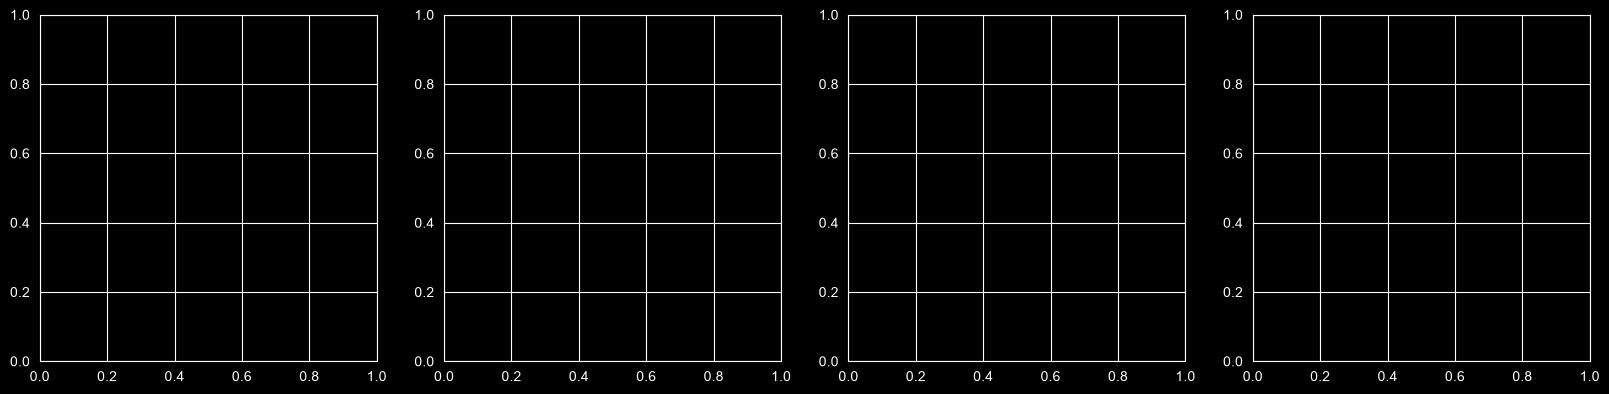

In [22]:
def plot_class_balance(y_train, y_val, y_test, class_names=("Норма", "Пневмония")):
    """
    Рисует три подграфика: распределение классов в train/val/test,
    а также сравнивает доли классов между выборками.
    """
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

    datasets = [
        ("Train", y_train, axes[0]),
        ("Validation", y_val, axes[1]),
        ("Test", y_test, axes[2]),
    ]

    for name, y, ax in datasets:
        counts = Counter(y)
        classes = sorted(counts.keys())
        labels = [class_names[c] for c in classes]
        values = [counts[c] for c in classes]
        total = sum(values)
        #colors = ['#4C9F70', '#D9534F']  # зелёный — норма, красный — пневмония

        bars = ax.bar(labels, values, edgecolor='black') #color=colors,
        ax.set_title(f"{name} (n = {total})", fontsize=13)
        ax.set_ylabel("Число примеров")
        for bar, v in zip(bars, values):
            pct = 100 * v / total
            ax.text(bar.get_x() + bar.get_width() / 2,
                    v + total * 0.01,
                    f"{v}\n({pct:.1f}%)",
                    ha='center', fontsize=10)

    # 4-й график: сравнение долей классов по выборкам
    ax = axes[3]
    splits = ["Train", "Val", "Test"]
    data = [y_train, y_val, y_test]
    ratios_pos = [100 * np.mean(y) for y in data]  # доля класса 1 (пневмония)

    x = np.arange(len(splits))
    width = 0.35
    ax.bar(x - width/2, [100 - r for r in ratios_pos], width,
           label=class_names[0], color='#4C9F70', edgecolor='black')
    ax.bar(x + width/2, ratios_pos, width,
           label=class_names[1], color='#D9534F', edgecolor='black')
    ax.set_xticks(x)
    ax.set_xticklabels(splits)
    ax.set_ylabel("Доля класса, %")
    ax.set_title("Сравнение долей классов", fontsize=13)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(0, 100)

    plt.suptitle("Баланс классов в PneumoniaMNIST", fontsize=15, y=1.02)
    plt.tight_layout()
    plt.show()

    # Печатаем числовые метрики
    print("\n" + "="*60)
    print("БАЛАНС КЛАССОВ")
    print("="*60)
    for name, y in zip(["Train", "Val", "Test"], [y_train, y_val, y_test]):
        pos = int(np.sum(y))
        neg = len(y) - pos
        ratio = pos / len(y)
        print(f"{name:6s}: всего = {len(y):5d} | "
              f"норма = {neg:5d} | пневмония = {pos:5d} | "
              f"доля пневмонии = {ratio:.2%}")


plot_class_balance(y_train, y_val, y_test)

### 3. Обучить деревья без ограничения глубины, с ограничением глубины, случайный лес и бустинг на этих данных.

In [ ]:
# Дерево без ограничений — переобучается
tree_full = DecisionTreeClassifier(class_weight='balanced', random_state=42)
tree_full.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_full.predict(X_train))
val_acc   = accuracy_score(y_val,   tree_full.predict(X_val))
print(f"Дерево (без ограничений): train={train_acc:.3f}, val={val_acc:.3f}")

# Дерево с ограничением глубины
tree_shallow = DecisionTreeClassifier(class_weight='balanced', max_depth=7, random_state=42)
tree_shallow.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_shallow.predict(X_train))
val_acc   = accuracy_score(y_val,   tree_shallow.predict(X_val))
print(f"Дерево (max_depth=5):     train={train_acc:.3f}, val={val_acc:.3f}")